# Transfer learning

Das Ziel des Transferlearning ist es, ein bereits trainiertes Modell auf eine andere Aufgabe zu trainieren. Die Idee dahinter ist den Teil des Netzwerks, der für die Extraktion von Merkmalen zuständig ist, zu "recyceln". Da dies in der Regel der teuerste Teil des Trainings ist, spart man sich dadurch eine Menge an Zeit. Das bedeutet, dass dieser Teil nicht neu trainiert werden muss, sondern die bereits trainierte Featurextraktion genauso gut für eine ähnliche Aufgabe verwendet werden kann. Aus diesem Grund sollte man ein bereits trainiertes Netzwerk nutzen, welches für eine ähnliche Aufgabe trainiert wurde. Lediglich die Klassifikationsschicht wird neu trainiert. Ziel dieses Notebooks ist es, ein Verständnis zu bekommen, was beim Transferlearning passiert.

Schauen Sie sich folgendes Notebook an und versuchen Sie den groben Ablauf zu verstehen.
Sie werden die meisten Befehle die Sie benötigen darin finden.
https://www.tensorflow.org/tutorials/images/transfer_learning

Für diese Aufgabe wollen wir das in der letzten Aufgabe trainierte Convolutional Neural Network, welches auf dem Mnist Datensatz trainiert wurde, auf eine andere Aufgabe trainieren. Die Aufgabe des Netzwerks soll es sein, Hexadezimalzahlen zu erkennen.
Hierzu verwenden wir den $\textit{emnist}$ Datensatz. Dieser beinhaltet zusätzlich das Alphabet (große und kleine Buchstaben). Näheres dazu unter https://pypi.org/project/emnist/ 

Gehen Sie dazu wie folgt vor:

    * Laden Sie ihr Modell aus der vorherigen Aufgabe mit tf.keras.models.load_model("Name des Modells") Falls Sie ihr Modell nicht gespeichert hatten, können Sie dies mit model.save("Name des Modells"), nachdem Sie erneut trainiert haben, tun.
      
    * Bereiten Sie den emnist-Datensatz wie in der vorherigen Aufgabe vor und sortieren Sie alle Kleinbuchstaben sowie alle Buchstaben, die nicht der Hexadezimalschreibweise angehören, aus!
      
    * Laden Sie das zuvor gespeicherte Modell und entfernen Sie die letzte Schicht ( model.pop() )
    
    * Frieren Sie das Modell ein, d.h. Sie setzen die Layer auf nicht trainierbar
    
    * Fügen Sie eine neue Schicht hinzu, sodass die verschiedenen Klassen (0-F) klassifiziert werden können (Wir beschränken uns hier auf die groß geschriebenen Buchstaben)
    
    * Trainieren Sie das Netzwerk mit den transformierten Labels
    
    * Plotten Sie wieder die Trainingskurven und erstellen sie eine confusion Matrix

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf
import tensorflow.keras as keras
from sklearn.metrics import confusion_matrix 
from extra_keras_datasets import emnist
from tensorflow.keras.models import load_model
from scipy.io import loadmat


In [99]:
# Vorbereiten von Nist

def load_emnist_data():
    mat = loadmat('emnist-balanced.mat')
    input_train = mat['dataset']['train'][0, 0]['images'][0, 0]
    target_train = mat['dataset']['train'][0, 0]['labels'][0, 0].flatten()
    input_test = mat['dataset']['test'][0, 0]['images'][0, 0]
    target_test = mat['dataset']['test'][0, 0]['labels'][0, 0].flatten()

    input_train = input_train.reshape((input_train.shape[0], 28, 28), order="F")
    input_test = input_test.reshape((input_test.shape[0], 28, 28), order="F")

    return (input_train, target_train), (input_test, target_test)

(input_train, target_train), (input_test, target_test) = load_emnist_data()


# Sortieren Sie alle Ziffern aus, die unerwünscht sind!
# Hinweis: np.where ist hierfür recht Hilfreich

input_train = input_train[np.where(target_train <= 15)]
target_train = target_train[np.where(target_train <= 15)]
input_test = input_test[np.where(target_test <= 15)]
target_test = target_test[np.where(target_test <= 15)]

X_val = input_train[0:8000] / 255
X_train = input_train[8000:] / 255
X_test = input_test / 255

Y_val = target_train[0:8000]
Y_train = target_train[8000:]
Y_test = target_test

#ursprüngliche variablen löschen
del input_train, target_train, input_test, target_test

#print(X_train.shape)
#print(X_val.shape)
#print(X_test.shape)
#print(Y_train.shape)
#print(Y_val.shape)
#print(Y_test.shape)


In [100]:
# Normalisieren Sie das Set und bringen es in die richtige "shape"
X_val = np.reshape(X_val, (X_val.shape[0],28,28,1))
X_train = np.reshape(X_train, (X_train.shape[0],28,28,1))
X_test = np.reshape(X_test, (X_test.shape[0],28,28,1))

# Labels in One-Hot-Kodierung umwandeln
Y_val = keras.utils.to_categorical(Y_val, 16)
Y_train = keras.utils.to_categorical(Y_train, 16)
Y_test = keras.utils.to_categorical(Y_test, 16)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_val.shape)
print(Y_test.shape)

(30400, 28, 28, 1)
(8000, 28, 28, 1)
(6400, 28, 28, 1)
(30400, 16)
(8000, 16)
(6400, 16)


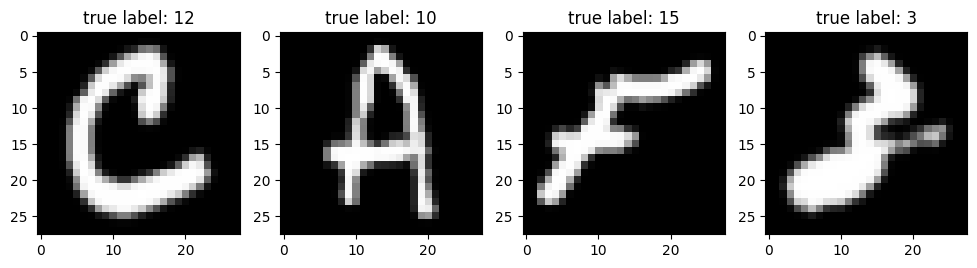

In [101]:
# Plotten Sie hier ein paar Ziffern!
plt.figure(figsize=(12,12))
for i in range(0,4):
    plt.subplot(1,4,(i+1))
    plt.imshow((X_train[i,:,:,0]),cmap="gray")
    plt.title('true label: '+ str(np.argmax(Y_train,axis=1)[i]))
    #plt.axis('off')

In [102]:
# Laden des Modells
base_model = tf.keras.models.load_model("../Abgabe 5/cnn_model_1.keras")

#Hier die letzte Schicht entfernen
base_model.pop()

<Dense name=dense_7, built=True>

In [103]:

base_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,470 (345.59 KB)

 Trainable params: 18,816 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 69,654 (272.09 KB)

In [104]:
# Modell einfrieren
for layer in base_model.layers:
    layer.trainable =False

# Basismodell als Ausgangspunkt nehmen
inputs = tf.keras.Input(shape=(28, 28,1))
x = base_model(inputs, training=False)

# Hier einen Dense-layer und einmal Softmax hinzufügen, sodass die verschiedenen Klassen vorhergesagt werden! können!
last_layer = tf.keras.layers.Dense(16)(x)
output     = tf.keras.layers.Activation('softmax')(last_layer)

# Modell Zusammenfügen
model = tf.keras.Model(inputs, output)

In [105]:
# Modell Kompilieren, Kostenfunktion categorical_crossentropy, Optimizer Adam mit der learningrate 1e-4
optimizer = keras.optimizers.Adam(learning_rate=1e-4)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

model.summary()

Model: "functional_69"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 1600)           │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │        25,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,432 (173.56 KB)

 Trainable params: 25,616 (100.06 KB)

 Non-trainable params: 18,816 (73.50 KB)

In [111]:
# Accuracy vor dem Transferlearning bestimmen
loss0, accuracy0 = model.evaluate(x = X_test,y = Y_test)

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9694 - loss: 0.1206


In [107]:
# Hier das Netzwerk für 10 Epochen trainieren!
epochs = 10
history=model.fit(X_train, Y_train,
                  batch_size=128,
                  epochs=epochs,
                  verbose=2,
                  validation_data=(X_val, Y_val)
                  )

Epoch 1/10
238/238 - 3s - 12ms/step - accuracy: 0.6199 - loss: 1.4081 - val_accuracy: 0.8670 - val_loss: 0.6038
Epoch 2/10
238/238 - 2s - 10ms/step - accuracy: 0.8945 - loss: 0.4616 - val_accuracy: 0.9191 - val_loss: 0.3567
Epoch 3/10
238/238 - 3s - 11ms/step - accuracy: 0.9257 - loss: 0.3126 - val_accuracy: 0.9359 - val_loss: 0.2692
Epoch 4/10
238/238 - 2s - 10ms/step - accuracy: 0.9405 - loss: 0.2465 - val_accuracy: 0.9463 - val_loss: 0.2215
Epoch 5/10
238/238 - 2s - 10ms/step - accuracy: 0.9488 - loss: 0.2080 - val_accuracy: 0.9523 - val_loss: 0.1923
Epoch 6/10
238/238 - 2s - 10ms/step - accuracy: 0.9556 - loss: 0.1818 - val_accuracy: 0.9574 - val_loss: 0.1715
Epoch 7/10
238/238 - 3s - 11ms/step - accuracy: 0.9597 - loss: 0.1627 - val_accuracy: 0.9616 - val_loss: 0.1556
Epoch 8/10
238/238 - 2s - 10ms/step - accuracy: 0.9631 - loss: 0.1481 - val_accuracy: 0.9631 - val_loss: 0.1448
Epoch 9/10
238/238 - 2s - 9ms/step - accuracy: 0.9658 - loss: 0.1364 - val_accuracy: 0.9655 - val_loss: 

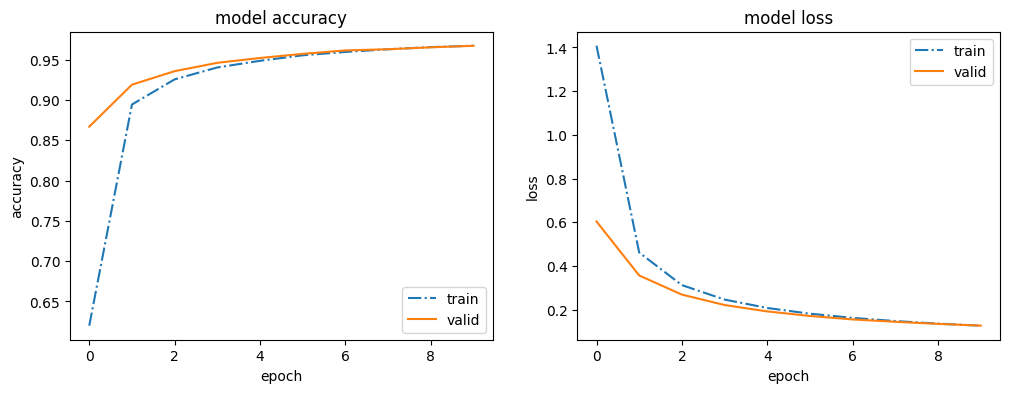

In [112]:
# Plotten der Trainingskurve wie in der Aufgabe zuvor
plt.figure(figsize=(12,4))
plt.subplot(1,2,(1))
plt.plot(history.history['accuracy'],linestyle='-.')
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='lower right')

plt.subplot(1,2,(2))
plt.plot(history.history['loss'],linestyle='-.')
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='upper right')

In [109]:
# Confusion Matrix erstellen
pred=model.predict(X_test)
print(confusion_matrix(np.argmax(Y_test,axis=1),np.argmax(pred,axis=1)))
acc_fc_orig = np.sum(np.argmax(Y_test,axis=1)==np.argmax(pred,axis=1))/len(pred)
print("Acc_fc_orig_flat = " , acc_fc_orig)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[377   0   0   0   1   0   2   1   0   0   0   0   0  18   1   0]
 [  0 394   2   0   0   0   0   2   0   0   1   0   0   0   0   1]
 [  1   0 385   3   0   0   0   1   2   0   2   1   1   3   1   0]
 [  2   0   0 387   0   3   0   0   2   3   0   2   0   0   0   1]
 [  1   0   1   0 383   0   1   0   1   4   4   0   0   1   0   4]
 [  1   0   1   2   0 388   1   0   0   2   0   0   3   0   0   2]
 [  0   1   0   0   0   1 397   0   0   0   0   0   1   0   0   0]
 [  0   1   2   0   1   0   0 392   0   3   0   0   0   0   0   1]
 [  0   0   0   0   1   1   0   0 384   4   0   5   0   1   2   2]
 [  2   0   0   0   3   0   0   5   2 388   0   0   0   0   0   0]
 [  0   0   2   0   4   0   1   0   0   0 389   3   1   0   0   0]
 [  4   0   0   3   1   0   1   1   7   0   4 373   0   1   5   0]
 [  5   0   1   0   0   0   3   0   0   0   0   0 388   0   2   1]
 [ 21   1   1   1   2   1   0   1   0   0   0   2   1 369   0   0]
 [  0   0   0   0   0